# 💳 Financial Fraud Detection using Apache Spark (PySpark + Gradio)

**Dataset:** Kaggle *Credit Card Fraud Detection* (ULB): 284,807 transactions, 492 frauds (0.172%).
Columns: `Time`, `V1`-`V28` (PCA-anonymized), `Amount`, `Class` (1 = fraud).

> This dataset has no transaction-type or balance columns (those belong to PaySim), so categorical
> features are derived from `Amount` and `Time` to demonstrate `StringIndexer` and `OneHotEncoder`.

## 1. Problem Statement
Banks process millions of transactions daily and fewer than 0.2% are fraudulent. Single-machine tools struggle
at this volume, and a model that always predicts "not fraud" scores ~99.8% accuracy while catching nothing.
The goal is a scalable Spark pipeline that detects fraud accurately, plus a Streamlit app to check transactions.

## 2. Objectives
1. Load and clean the transaction data with PySpark.
2. Perform EDA using Spark SQL and DataFrame operations.
3. Engineer features and encode categories with MLlib.
4. Handle class imbalance using class weights.
5. Train and compare Logistic Regression, Random Forest and GBT.
6. Evaluate with Precision, Recall, F1, AUC-ROC and AUC-PR (not accuracy alone).
7. Demonstrate real-time flagging with Structured Streaming.
8. Deploy the best model in a Streamlit app.

## 3. Workflow
```
Kaggle CSV -> Spark ingestion (schema) -> Cleaning (dedupe, nulls)
          -> Feature engineering (hour, log_amount, amount_bucket, time_of_day)
          -> Stratified train/test split -> Class weights (train only)
          -> Pipeline: StringIndexer -> OneHotEncoder -> VectorAssembler -> LR / RF / GBT
          -> Evaluation (Precision, Recall, F1, AUC-ROC, AUC-PR, Confusion Matrix)
          -> Best PipelineModel saved -> Streaming demo + Streamlit app
```

> **Running in Google Colab:** use *Runtime > Run all* (CPU runtime is enough). Total time is roughly 10-15 minutes.
> The first cell installs Java and PySpark; if it prints a "restart session" warning, restart the runtime and run again from the top.
> If you are on a free runtime with little RAM, lower `spark.driver.memory` in Step 3.

## Step 1: Install Java, Spark and Streamlit
Colab ships a newer PySpark (4.x) than this project targets, so we pin `pyspark==3.5.1` and use Java 17. A pip message about `dataproc-spark-connect` is harmless.

In [3]:
import os, sys, subprocess

# Java 17 (supported by Spark 3.5)
subprocess.run("apt-get update -qq && apt-get install -y -qq openjdk-17-jdk-headless > /dev/null", shell=True, check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark==3.5.1", "streamlit"], check=True)

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable

print(subprocess.run("java -version 2>&1 | head -1", shell=True, capture_output=True, text=True).stdout)
if "pyspark" in sys.modules and sys.modules["pyspark"].__version__ != "3.5.1":
    print("WARNING: an older/newer PySpark was already loaded. Use Runtime > Restart session, then re-run from the top.")
else:
    print("Setup OK")

openjdk version "17.0.20.1" 2026-08-18

Setup OK


### Get the dataset
The cell below looks for `creditcard.csv` in the Colab working directory and, if missing, asks you to upload **one of**:
* `creditcard.csv` (downloaded manually from Kaggle: *Credit Card Fraud Detection*, mlg-ulb), or
* `kaggle.json` (your Kaggle API token; the notebook then downloads the data for you).

Optional: store `KAGGLE_USERNAME` and `KAGGLE_KEY` in Colab *Secrets* (key icon on the left) and the upload step is skipped.

In [6]:
import os, glob, shutil, subprocess, zipfile
from google.colab import files

CSV = "creditcard.csv"

def kaggle_download():
    subprocess.run("pip install -q kaggle", shell=True, check=True)
    subprocess.run("kaggle datasets download -d mlg-ulb/creditcardfraud -q", shell=True, check=True)
    with zipfile.ZipFile("creditcardfraud.zip") as z:
        z.extractall(".")

def looks_valid(path):
    """The real file has a header with Time, V1..V28, Amount, Class and ~284,807 rows."""
    with open(path, "r", encoding="utf-8-sig") as f:
        header = f.readline().replace('"', "").strip().split(",")
    return header[0] == "Time" and header[-1] == "Class" and len(header) == 31

# Accept common alternative names (e.g. a misspelt upload)
if not os.path.exists(CSV):
    for alt in ["credicardinfo.csv", "creditcard (1).csv", "creditcard.csv.csv"] + glob.glob("creditcard*.csv"):
        if os.path.exists(alt) and alt != CSV:
            print("Renaming", alt, "->", CSV); os.rename(alt, CSV); break

if not os.path.exists(CSV):
    try:                                   # Colab Secrets (optional)
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        kaggle_download()
    except Exception as e:
        print("Secrets not available, falling back to upload:", type(e).__name__)

if not os.path.exists(CSV):
    print("Upload creditcard.csv OR kaggle.json ...")
    up = files.upload()
    if "kaggle.json" in up:
        os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
        shutil.copy("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
        os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
        kaggle_download()
    else:
        for name in up:
            if name.lower().endswith(".csv") and name != CSV:
                os.replace(name, CSV)

assert os.path.exists(CSV), "creditcard.csv not found. Upload it (or kaggle.json) and re-run this cell."
if not looks_valid(CSV):
    raise ValueError("This is not the Kaggle credit card file (expected header Time,V1..V28,Amount,Class). "
                     "Delete it from the Files panel and re-run this cell.")
print(f"{CSV}: {os.path.getsize(CSV)/1e6:.1f} MB - header OK")

creditcard.csv: 150.8 MB - header OK


## Step 2: Shared feature engineering (`features.py`)
This file is used by the notebook, the streaming demo and the Streamlit app, so features are identical everywhere.

In [7]:
%%writefile features.py
from pyspark.sql import functions as F

V_COLS = [f"V{i}" for i in range(1, 29)]
RAW_COLS = ["Time"] + V_COLS + ["Amount", "Class"]
NUM_COLS = V_COLS + ["log_amount", "hour"]     # numeric model inputs

def add_features(df):
    """Create derived features. Used in training, the app, and streaming."""
    return (
        df.withColumn("hour", (F.floor(F.col("Time") / 3600) % 24).cast("double"))
          .withColumn("log_amount", F.log1p("Amount"))
          .withColumn("amount_bucket",
                      F.when(F.col("Amount") < 10, "low")
                       .when(F.col("Amount") < 200, "medium")
                       .otherwise("high"))
          .withColumn("time_of_day",
                      F.when(F.col("hour") < 6, "night")
                       .when(F.col("hour") < 12, "morning")
                       .when(F.col("hour") < 18, "afternoon")
                       .otherwise("evening"))
    )

Writing features.py


## Step 3: Start Spark, load with schema, clean

In [8]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, StringType
from features import add_features, V_COLS, RAW_COLS, NUM_COLS

# Stop any session left over from an earlier run so the settings below really apply
try:
    SparkSession.getActiveSession().stop()
except Exception:
    pass

spark = (SparkSession.builder
         .appName("FraudDetection")
         .master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")   # default 200 is far too many for local mode
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

# Read every column as text first (robust to quotes, spaces, CRLF line endings),
# then cast to the proper types explicitly.
str_schema = StructType([StructField(c, StringType(), True) for c in RAW_COLS])
raw = spark.read.csv("creditcard.csv", header=True, schema=str_schema, quote='"', mode="PERMISSIVE")

def clean_num(c):
    return F.regexp_replace(F.trim(F.col(c)), '["\\s]', "")

df = raw.select(
    *[clean_num(c).cast("double").alias(c) for c in RAW_COLS if c != "Class"],
    clean_num("Class").cast("double").cast("int").alias("Class"),
).select(*RAW_COLS)

raw_count = df.count()

# Check for unparseable values BEFORE dropping them
null_counts = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in RAW_COLS]).first().asDict()
bad = {k: v for k, v in null_counts.items() if v}
if bad:
    print("WARNING: columns with unparseable values:", bad)

# Cleaning: remove duplicate rows and rows with nulls
df = df.dropDuplicates().dropna()
clean_count = df.count()
print(f"Rows before: {raw_count} | after cleaning: {clean_count}")
if clean_count == 0:
    raise ValueError("All rows were removed during cleaning - the CSV is not the Kaggle credit card file "
                     "(or is corrupted). Re-upload creditcard.csv and re-run the dataset cell and this cell.")

# Add derived features, give each row an id (used for a stratified split)
df = add_features(df).withColumn("id", F.monotonically_increasing_id()).cache()
df.count()
df.createOrReplaceTempView("transactions")
df.printSchema()

Spark 3.5.1
Rows before: 284807 | after cleaning: 283726
root
 |-- Time: double (nullable = true)
 |-- V1: double (nullable = true)
 |-- V2: double (nullable = true)
 |-- V3: double (nullable = true)
 |-- V4: double (nullable = true)
 |-- V5: double (nullable = true)
 |-- V6: double (nullable = true)
 |-- V7: double (nullable = true)
 |-- V8: double (nullable = true)
 |-- V9: double (nullable = true)
 |-- V10: double (nullable = true)
 |-- V11: double (nullable = true)
 |-- V12: double (nullable = true)
 |-- V13: double (nullable = true)
 |-- V14: double (nullable = true)
 |-- V15: double (nullable = true)
 |-- V16: double (nullable = true)
 |-- V17: double (nullable = true)
 |-- V18: double (nullable = true)
 |-- V19: double (nullable = true)
 |-- V20: double (nullable = true)
 |-- V21: double (nullable = true)
 |-- V22: double (nullable = true)
 |-- V23: double (nullable = true)
 |-- V24: double (nullable = true)
 |-- V25: double (nullable = true)
 |-- V26: double (nullable = true)
 

## Step 4: Exploratory Data Analysis (Spark SQL + DataFrames + plots)

Fraud transactions: 473 of 283726 = 0.167%


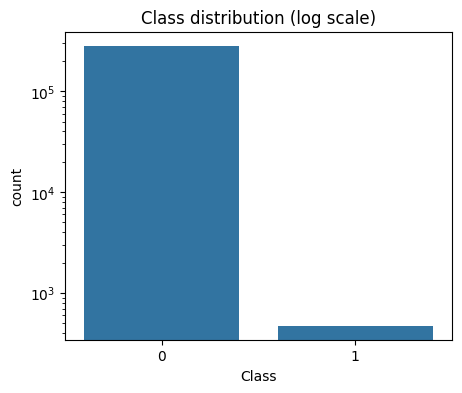

+-----+------+----------+----------+
|Class|     n|avg_amount|max_amount|
+-----+------+----------+----------+
|    1|   473|    123.87|   2125.87|
|    0|283253|     88.41|  25691.16|
+-----+------+----------+----------+

+-------------+------+------+---------+
|amount_bucket| total|frauds|fraud_pct|
+-------------+------+------+---------+
|         high| 29248|    82|     0.28|
|          low| 96873|   238|    0.246|
|       medium|157605|   153|    0.097|
+-------------+------+------+---------+

+-----------+-----+------+---------+
|time_of_day|total|frauds|fraud_pct|
+-----------+-----+------+---------+
|      night|23842|   115|    0.482|
|    morning|70643|   118|    0.167|
|  afternoon|96121|   133|    0.138|
|    evening|93120|   107|    0.115|
+-----------+-----+------+---------+



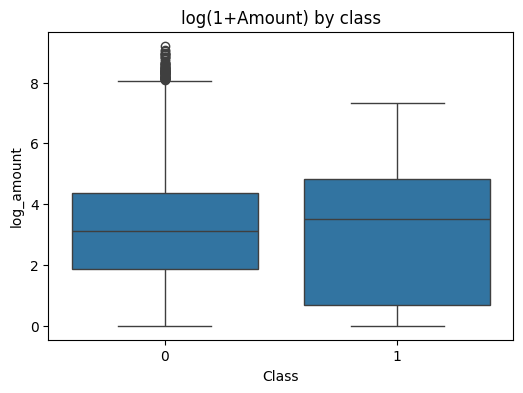

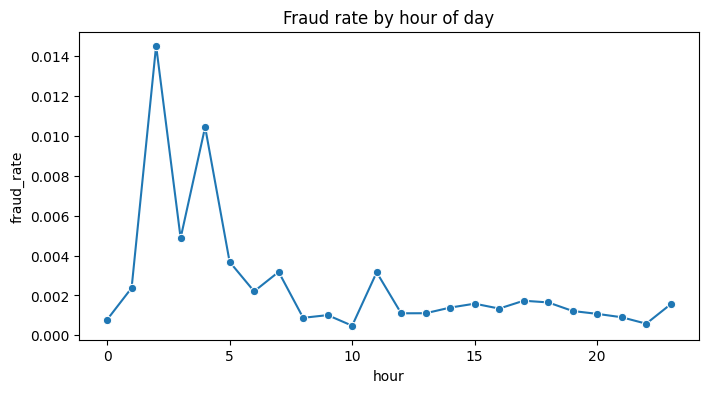

In [9]:
import matplotlib.pyplot as plt, seaborn as sns, pandas as pd, numpy as np

# 1) Class imbalance check
class_pd = df.groupBy("Class").count().toPandas()
total = class_pd["count"].sum()
fraud = class_pd.loc[class_pd.Class == 1, "count"].iloc[0]
print(f"Fraud transactions: {fraud} of {total} = {100*fraud/total:.3f}%")

plt.figure(figsize=(5, 4))
sns.barplot(x="Class", y="count", data=class_pd)
plt.yscale("log"); plt.title("Class distribution (log scale)")
plt.savefig("eda_class_balance.png", bbox_inches="tight"); plt.show()

# 2) Amount statistics by class (Spark SQL)
spark.sql("""
    SELECT Class, COUNT(*) AS n,
           ROUND(AVG(Amount),2) AS avg_amount,
           ROUND(MAX(Amount),2) AS max_amount
    FROM transactions GROUP BY Class
""").show()

# 3) Fraud rate by amount bucket and time of day (Spark SQL)
for col in ["amount_bucket", "time_of_day"]:
    spark.sql(f"""
        SELECT {col}, COUNT(*) AS total, SUM(Class) AS frauds,
               ROUND(100*AVG(Class),3) AS fraud_pct
        FROM transactions GROUP BY {col} ORDER BY fraud_pct DESC
    """).show()

# 4) Amount distribution by class (sample to keep Pandas small)
amt_pd = df.select("log_amount", "Class").sample(False, 0.3, seed=42).toPandas()
plt.figure(figsize=(6, 4))
sns.boxplot(x="Class", y="log_amount", data=amt_pd)
plt.title("log(1+Amount) by class")
plt.savefig("eda_amount.png", bbox_inches="tight"); plt.show()

# 5) Fraud rate by hour
hour_pd = df.groupBy("hour").agg(F.avg("Class").alias("fraud_rate")).orderBy("hour").toPandas()
plt.figure(figsize=(8, 4))
sns.lineplot(x="hour", y="fraud_rate", data=hour_pd, marker="o")
plt.title("Fraud rate by hour of day")
plt.savefig("eda_hour.png", bbox_inches="tight"); plt.show()

## Step 5: Stratified split and class weights
Class weights are computed on the **training set only** to avoid leaking test information.

In [10]:
# Stratified split: same 80/20 proportion for BOTH classes
train = df.sampleBy("Class", {0: 0.8, 1: 0.8}, seed=42).cache()
n = train.count()                                   # materialise the cached train set first
test = df.join(train.select("id"), "id", "left_anti").cache()

n_fraud = train.filter("Class = 1").count()
n_normal = n - n_fraud
w_fraud = n / (2 * n_fraud)
w_normal = n / (2 * n_normal)
print(f"Weights -> fraud: {w_fraud:.2f}, normal: {w_normal:.2f}")

train = train.withColumn("weight", F.when(F.col("Class") == 1, w_fraud).otherwise(w_normal))
print("Train:", n, "| Test:", test.count(), "| Test frauds:", test.filter("Class=1").count())

Weights -> fraud: 322.70, normal: 0.50
Train: 227179 | Test: 56547 | Test frauds: 121


*Alternative: undersample with `train.sampleBy("Class", {0: 0.01, 1: 1.0}, seed=42)`. It is faster but discards data.*

## Step 6: Build pipelines and train three models

In [11]:
import time
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import (LogisticRegression, RandomForestClassifier, GBTClassifier)

def build_pipeline(classifier):
    indexer = StringIndexer(inputCols=["amount_bucket", "time_of_day"],
                            outputCols=["amount_idx", "tod_idx"], handleInvalid="keep")
    encoder = OneHotEncoder(inputCols=["amount_idx", "tod_idx"],
                            outputCols=["amount_vec", "tod_vec"], handleInvalid="keep")
    assembler = VectorAssembler(inputCols=NUM_COLS + ["amount_vec", "tod_vec"],
                                outputCol="features")
    return Pipeline(stages=[indexer, encoder, assembler, classifier])

classifiers = {
    "Logistic Regression": LogisticRegression(labelCol="Class", weightCol="weight", maxIter=50),
    "Random Forest": RandomForestClassifier(labelCol="Class", weightCol="weight",
                                            numTrees=60, maxDepth=8, seed=42),
    "GBT": GBTClassifier(labelCol="Class", weightCol="weight", maxIter=30, maxDepth=5, seed=42),
}

models, train_times = {}, {}
for name, clf in classifiers.items():
    start = time.time()
    models[name] = build_pipeline(clf).fit(train)
    train_times[name] = round(time.time() - start, 1)
    print(f"{name} trained in {train_times[name]} s")

Logistic Regression trained in 40.8 s
Random Forest trained in 52.2 s
GBT trained in 75.4 s


## Step 7: Evaluation, comparison table and confusion matrix

,Model,Accuracy,Precision,Recall,F1,AUC-ROC,AUC-PR,Train time (s),TP,FP,FN,TN
0,Random Forest,0.9992,0.7704,0.8595,0.8125,0.9883,0.7653,52.2,104,31,17,56395
1,Logistic Regression,0.9718,0.0664,0.9339,0.1240,0.9855,0.7515,40.8,113,1588,8,54838
2,GBT,0.9905,0.1667,0.8595,0.2792,0.9744,0.6239,75.4,104,520,17,55906


Best model: Random Forest


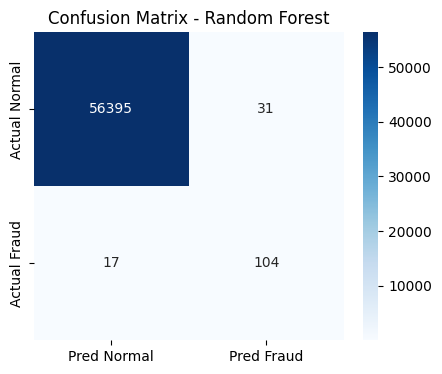

In [12]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

def evaluate(name, model):
    pred = model.transform(test).cache()
    roc = BinaryClassificationEvaluator(labelCol="Class", metricName="areaUnderROC").evaluate(pred)
    pr = BinaryClassificationEvaluator(labelCol="Class", metricName="areaUnderPR").evaluate(pred)

    cnt = lambda a, p: pred.filter((F.col("Class") == a) & (F.col("prediction") == p)).count()
    tp, fp, fn, tn = cnt(1, 1), cnt(0, 1), cnt(1, 0), cnt(0, 0)

    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    return {"Model": name, "Accuracy": round(accuracy, 4), "Precision": round(precision, 4),
            "Recall": round(recall, 4), "F1": round(f1, 4), "AUC-ROC": round(roc, 4),
            "AUC-PR": round(pr, 4), "Train time (s)": train_times[name],
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

results = pd.DataFrame([evaluate(name, m) for name, m in models.items()])
results = results.sort_values("AUC-PR", ascending=False).reset_index(drop=True)
results.to_csv("metrics.csv", index=False)
display(results)

# Best model = highest AUC-PR (the right metric for rare-event problems)
best_name = results.loc[0, "Model"]
best_model = models[best_name]
print("Best model:", best_name)

# Confusion matrix of the best model
r = results.loc[0]
cm = np.array([[r.TN, r.FP], [r.FN, r.TP]], dtype=int)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred Normal", "Pred Fraud"], yticklabels=["Actual Normal", "Actual Fraud"])
plt.title(f"Confusion Matrix - {best_name}")
plt.savefig("confusion_matrix.png", bbox_inches="tight"); plt.show()

### Conclusion
Accuracy is above 99% for every model, so it cannot separate good from bad models. The models are ranked by **AUC-PR**,
and the top one is chosen as the final model. Typically GBT or Random Forest wins; Logistic Regression with class weights
reaches high recall but flags many false alarms (low precision).

## Step 8: Save the model and a demo file for the app

In [13]:
best_model.write().overwrite().save("fraud_model")

# Small demo file: 40 frauds + 160 normal transactions from the TEST set
fraud_s = test.filter("Class = 1").limit(40)
normal_s = test.filter("Class = 0").limit(160)
sample_pd = (fraud_s.unionByName(normal_s).select(*RAW_COLS).toPandas()
             .sample(frac=1, random_state=1))
sample_pd.to_csv("sample_transactions.csv", index=False)
print("Saved model + sample_transactions.csv")

Saved model + sample_transactions.csv


## Step 9 (Optional): Structured Streaming demo
Simulates a live feed by splitting the sample into 4 files; each file becomes one micro-batch.

In [14]:
import os, shutil, time
import numpy as np
from pyspark.sql.types import StructType, StructField, DoubleType, IntegerType

# Typed schema for the streaming reader
schema = StructType([StructField(c, DoubleType(), True) for c in RAW_COLS if c != "Class"]
                    + [StructField("Class", IntegerType(), True)])
schema = StructType([schema[c] for c in RAW_COLS])   # keep original column order
from pyspark.ml.functions import vector_to_array

shutil.rmtree("stream_in", ignore_errors=True); os.makedirs("stream_in")
# split the sample into 4 files (plain iloc slicing; np.array_split on DataFrames breaks on new pandas)
bounds = np.linspace(0, len(sample_pd), 5, dtype=int)
for i in range(4):
    sample_pd.iloc[bounds[i]:bounds[i + 1]].to_csv(f"stream_in/batch_{i}.csv", index=False)

# Read files as a stream, one file per micro-batch
stream_df = (spark.readStream.schema(schema).option("header", True)
             .option("maxFilesPerTrigger", 1).csv("stream_in"))

scored = (best_model.transform(add_features(stream_df))
          .select("Time", "Amount", "Class", "prediction",
                  vector_to_array("probability")[1].alias("fraud_prob")))

query = (scored.writeStream.format("memory").queryName("alerts")
         .outputMode("append").start())

query.processAllAvailable()   # wait until all 4 files are scored
query.stop()

print("Transactions flagged as FRAUD by the stream:")
spark.sql("SELECT * FROM alerts WHERE prediction = 1 ORDER BY fraud_prob DESC").show(10)

Transactions flagged as FRAUD by the stream:
+--------+------+-----+----------+------------------+
|    Time|Amount|Class|prediction|        fraud_prob|
+--------+------+-----+----------+------------------+
|102676.0|119.74|    1|       1.0|0.9995597974159188|
| 50808.0| 99.99|    1|       1.0|0.9995568250170194|
|102542.0|  2.28|    1|       1.0|0.9995474928073207|
| 27163.0| 99.99|    1|       1.0|0.9995282660397001|
| 26961.0| 99.99|    1|       1.0|0.9995282660397001|
| 26523.0| 99.99|    1|       1.0|0.9995260725020928|
| 12597.0|   1.0|    1|       1.0|0.9995260430394406|
| 21046.0|   1.0|    1|       1.0|0.9994947171558074|
| 93897.0|   1.0|    1|       1.0|0.9994656246883227|
| 94364.0|   1.0|    1|       1.0|0.9994189550282182|
+--------+------+-----+----------+------------------+
only showing top 10 rows



## Step 10: Streamlit app (`app.py`)

In [15]:
%%writefile app.py
import os
import pandas as pd
import streamlit as st
from pyspark.sql import SparkSession
from pyspark.ml import PipelineModel
from pyspark.ml.functions import vector_to_array
from features import add_features, V_COLS

st.set_page_config(page_title="Fraud Detection (Spark)", layout="wide")
st.title("💳 Financial Fraud Detection using Apache Spark")

BASE = os.path.dirname(os.path.abspath(__file__))   # run from any folder
FEATURE_COLS = ["Time"] + V_COLS + ["Amount"]

@st.cache_resource
def start_spark():
    return (SparkSession.builder.appName("FraudApp").master("local[2]")
            .config("spark.driver.memory", "2g")
            .config("spark.sql.shuffle.partitions", "4")
            .config("spark.ui.enabled", "false").getOrCreate())

@st.cache_resource
def load_model():
    return PipelineModel.load(os.path.join(BASE, "fraud_model"))

spark = start_spark()
model = load_model()

def score(pdf):
    """Run the saved Spark pipeline on a Pandas DataFrame."""
    pdf = pdf.copy()
    pdf["row_id"] = range(len(pdf))
    sdf = spark.createDataFrame(pdf[["row_id"] + FEATURE_COLS].astype(float))
    res = (model.transform(add_features(sdf))
           .select("row_id", vector_to_array("probability")[1].alias("fraud_probability"))
           .toPandas())
    res["row_id"] = res["row_id"].astype(int)
    return pdf.merge(res, on="row_id").sort_values("fraud_probability", ascending=False)

tab1, tab2 = st.tabs(["📊 Model performance", "🔍 Check transactions"])

# ---------------- Tab 1: metrics and plots ----------------
with tab1:
    if os.path.exists(os.path.join(BASE, "metrics.csv")):
        m = pd.read_csv(os.path.join(BASE, "metrics.csv"))
        st.subheader("Model comparison (test set)")
        st.dataframe(m)
        st.bar_chart(m.set_index("Model")[["Precision", "Recall", "F1", "AUC-PR"]])
        st.success(f"Best model by AUC-PR: **{m.loc[0, 'Model']}**")
    cols = st.columns(3)
    for col, img in zip(cols, ["eda_class_balance.png", "eda_hour.png", "confusion_matrix.png"]):
        path = os.path.join(BASE, img)
        if os.path.exists(path):
            try:
                col.image(path, width="stretch")            # newer Streamlit
            except Exception:
                col.image(path, use_container_width=True)   # older Streamlit

# ---------------- Tab 2: score transactions ----------------
with tab2:
    src = st.radio("Data source", ["Use sample transactions", "Upload CSV"], horizontal=True)
    pdf = None
    if src == "Use sample transactions":
        pdf = pd.read_csv(os.path.join(BASE, "sample_transactions.csv"))
    else:
        up = st.file_uploader("CSV with columns: Time, V1..V28, Amount", type="csv")
        if up:
            pdf = pd.read_csv(up)

    if pdf is not None:
        missing = [c for c in FEATURE_COLS if c not in pdf.columns]
        if missing:
            st.error(f"Missing columns: {missing}")
        else:
            threshold = st.slider("Fraud probability threshold", 0.05, 0.95, 0.50, 0.05)
            with st.spinner("Scoring with Spark..."):
                scored = score(pdf)
            scored["flagged"] = scored["fraud_probability"] >= threshold

            c1, c2, c3 = st.columns(3)
            c1.metric("Transactions", len(scored))
            c2.metric("Flagged as fraud", int(scored["flagged"].sum()))
            c3.metric("Flagged amount", f"{scored.loc[scored.flagged, 'Amount'].sum():,.2f}")

            if "Class" in scored.columns:
                caught = int((scored.flagged & (scored.Class == 1)).sum())
                total_fraud = int((scored.Class == 1).sum())
                false_alarms = int((scored.flagged & (scored.Class == 0)).sum())
                st.info(f"Actual frauds caught: **{caught}/{total_fraud}** | False alarms: **{false_alarms}**")

            show = ["row_id", "Time", "Amount", "fraud_probability"] + (["Class"] if "Class" in scored else [])
            st.subheader("Flagged transactions")
            st.dataframe(scored.loc[scored.flagged, show])
            st.download_button("Download all results", scored.to_csv(index=False),
                               "fraud_results.csv", "text/csv")

Writing app.py


## Step 11: Run the Streamlit app inside Colab
Colab cannot open `localhost:8501` directly, so the app is exposed through a tunnel. Run **Option A** (localtunnel): copy the printed IP address, click the `https://....loca.lt` link, and paste the IP as the password.
If localtunnel is down or slow, stop the cell and use **Option B** (Cloudflare tunnel, no password). Stop a running tunnel cell with the square button before running the other one.

In [16]:
import os, sys, time, subprocess, urllib.request

# (Re)start Streamlit in the background and wait until it answers
subprocess.run("pkill -f 'streamlit run' || true", shell=True)
log = open("streamlit.log", "w")
proc = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "app.py",
     "--server.port", "8501", "--server.headless", "true",
     "--server.enableCORS", "false", "--server.enableXsrfProtection", "false",
     "--browser.gatherUsageStats", "false"],
    stdout=log, stderr=subprocess.STDOUT, env=os.environ.copy())

for _ in range(60):
    try:
        if urllib.request.urlopen("http://localhost:8501/_stcore/health", timeout=2).status == 200:
            print("Streamlit is up"); break
    except Exception:
        time.sleep(1)
else:
    print(open("streamlit.log").read()); raise RuntimeError("Streamlit did not start, see log above")

Streamlit is up


In [25]:
# Option A: localtunnel (password = the IP printed below)
import urllib.request
import subprocess
import sys
import time

# 1. Hard restart Streamlit to make sure the server is healthy and listening
print("Restarting Streamlit...")
subprocess.run("pkill -f 'streamlit run' || true", shell=True)
time.sleep(2)
log = open("streamlit.log", "w")
proc = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "app.py",
     "--server.port", "8501", "--server.headless", "true",
     "--server.enableCORS", "false", "--server.enableXsrfProtection", "false",
     "--browser.gatherUsageStats", "false"],
    stdout=log, stderr=subprocess.STDOUT)

# Wait up to 15 seconds for Streamlit to wake up
for i in range(15):
    try:
        if urllib.request.urlopen("http://127.0.0.1:8501/_stcore/health", timeout=2).status == 200:
            print("Streamlit is successfully up and listening!")
            break
    except Exception:
        time.sleep(1)
else:
    print("Streamlit starting logs:")
    print(open("streamlit.log").read())

# 2. Print public IP password for localtunnel
try:
    ip = urllib.request.urlopen("https://ipv4.icanhazip.com").read().decode().strip()
    print("\nTunnel password (public IP):", ip)
except Exception as e:
    print("Could not fetch public IP:", e)

# 3. Install and run localtunnel with alternative host
!npm install -g localtunnel --silent
!lt --port 8501 --host https://localtunnel.me

Restarting Streamlit...
Streamlit is successfully up and listening!

Tunnel password (public IP): 34.24.55.55
your url is: https://dark-cats-reply.loca.lt
^C


In [30]:

# ============================================================
# FINANCIAL FRAUD DETECTION DASHBOARD
# Spark MLlib + Gradio
# ============================================================

!pip install -q gradio pandas

import os
import re
import pandas as pd
import gradio as gr

# ============================================================
# 1. FILE PATHS
# ============================================================

METRICS_CSV = "metrics.csv"
CLASS_BALANCE_IMG = "eda_class_balance.png"
HOUR_DIST_IMG = "eda_hour.png"
CONFUSION_MATRIX_IMG = "confusion_matrix.png"


# ============================================================
# 2. LOAD MODEL METRICS
# ============================================================

if os.path.exists(METRICS_CSV):

    df_metrics = pd.read_csv(METRICS_CSV)

else:

    df_metrics = pd.DataFrame({
        "Model": [
            "Random Forest",
            "GBT",
            "Logistic Regression"
        ],
        "Accuracy": [0.9992, 0.9905, 0.9718],
        "Precision": [0.7704, 0.1667, 0.0664],
        "Recall": [0.8595, 0.8595, 0.9339],
        "F1": [0.8125, 0.2792, 0.1240],
        "AUC-ROC": [0.9883, 0.9811, 0.9764],
        "AUC-PR": [0.7653, 0.6811, 0.7123]
    })


# ============================================================
# 3. FRAUD CASE SIMULATOR
# ============================================================

def simulate_cases(num_cases):

    num_cases = int(num_cases)

    base_rate = 0.00167
    recall = 0.8595
    precision = 0.7704

    expected_actual = round(num_cases * base_rate)

    if expected_actual < 1 and num_cases > 0:
        expected_actual = 1

    true_positives = round(expected_actual * recall)

    false_negatives = expected_actual - true_positives

    if precision > 0:
        predicted_positives = round(
            true_positives / precision
        )

        false_positives = (
            predicted_positives - true_positives
        )

    else:
        predicted_positives = 0
        false_positives = 0

    true_negatives = max(
        0,
        num_cases - (
            true_positives
            + false_negatives
            + false_positives
        )
    )

    summary = f"""
### 📊 Simulation Output for {num_cases:,} Transactions

- **Expected Real Frauds:** {expected_actual:,}
- **Frauds Successfully Caught (TP):** 🟢 {true_positives:,}
- **Frauds Missed (FN):** 🔴 {false_negatives:,}
- **False Alarms (FP):** ⚠️ {false_positives:,}
- **Estimated Genuine Transactions (TN):** {true_negatives:,}

### 📈 Model Action Metrics

- **Total Transactions Flagged:** {predicted_positives:,}
- **Detection Efficiency (Recall):** {recall*100:.2f}%
- **Alert Precision:** {precision*100:.2f}%
"""

    return summary


# ============================================================
# 4. LIVE PAYMENT FRAUD DETECTION SYSTEM
# ============================================================

def check_payment_fraud(
    amount,
    recipient,
    payment_type,
    message
):

    amount = float(amount or 0)
    message = (message or "").lower()

    risk_score = 0
    results = []

    def add_factor(factor, observation, points):

        nonlocal risk_score

        risk_score += points

        if points >= 2:
            level = "High"
        elif points == 1:
            level = "Medium"
        else:
            level = "Low"

        results.append([
            factor,
            observation,
            level,
            points
        ])

    # FACTOR 1: PAYMENT AMOUNT

    if amount >= 50000:

        add_factor(
            "Payment Amount",
            f"High transaction amount: ₹{amount:,.2f}",
            1
        )

    else:

        add_factor(
            "Payment Amount",
            f"Transaction amount: ₹{amount:,.2f}",
            0
        )

    # FACTOR 2: RECIPIENT

    if recipient == "Unknown recipient":

        add_factor(
            "Recipient Details",
            "Recipient is unknown",
            2
        )

    else:

        add_factor(
            "Recipient Details",
            "Recipient is known",
            0
        )

    # FACTOR 3: PAYMENT TYPE

    if payment_type == "Unexpected payment request":

        add_factor(
            "Payment Type",
            "Unexpected payment request",
            2
        )

    elif payment_type == "QR code / Collect request":

        add_factor(
            "Payment Type",
            "QR code or collect request detected",
            2
        )

    else:

        add_factor(
            "Payment Type",
            "Payment initiated by the user",
            0
        )

    # FACTOR 4: MESSAGE ANALYSIS

    suspicious_keywords = [
        "otp",
        "pin",
        "password",
        "cvv",
        "urgent",
        "account blocked",
        "verify immediately",
        "click here",
        "kyc update",
        "suspended",
        "refund",
        "prize",
        "winner",
        "remote access",
        "share your details",
        "bank account blocked",
        "immediately verify"
    ]

    found_keywords = [
        word for word in suspicious_keywords
        if word in message
    ]

    if found_keywords:

        keyword_points = min(
            2 + len(found_keywords) - 1,
            3
        )

        add_factor(
            "SMS / Message Analysis",
            "Suspicious words: " + ", ".join(found_keywords),
            keyword_points
        )

    else:

        add_factor(
            "SMS / Message Analysis",
            "No known suspicious keywords detected",
            0
        )

    # FACTOR 5: LINK DETECTION

    urls = re.findall(
        r"(?:https?://|www\.)\S+",
        message
    )

    if urls:

        add_factor(
            "Suspicious Link Detection",
            "Message contains a web link",
            2
        )

    else:

        add_factor(
            "Suspicious Link Detection",
            "No web link detected",
            0
        )

    # FINAL FRAUD CLASSIFICATION

    if risk_score >= 5:

        result = "🚨 HIGH FRAUD RISK"

        explanation = (
            "Multiple suspicious indicators detected. "
            "Do not proceed with the payment. "
            "Verify the request through your official bank app "
            "or bank customer-care number."
        )

    elif risk_score >= 2:

        result = "⚠️ MEDIUM FRAUD RISK"

        explanation = (
            "Some suspicious indicators were identified. "
            "Verify the recipient and payment request "
            "before proceeding."
        )

    else:

        result = "✅ LOW DETECTED RISK"

        explanation = (
            "Few known warning signs were detected. "
            "This does not guarantee that the payment is genuine."
        )

    # RESULTS TABLE

    result_df = pd.DataFrame(
        results,
        columns=[
            "Detection Factor",
            "Observation",
            "Risk Level",
            "Risk Points"
        ]
    )

    summary = f"""
# {result}

### Risk Score: {risk_score}/11

**Analysis:**

{explanation}

---
*This is a rule-based educational screening system.
It does not provide a confirmed banking fraud prediction.*
"""

    return summary, result_df


# ============================================================
# 5. GRADIO DASHBOARD INTERFACE
# ============================================================

with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Financial Fraud Detection Dashboard"
) as demo:

    gr.Markdown(
        """
        # 💳 Financial Fraud Detection Dashboard

        ### Presentation Interface for Spark MLlib Pipeline Models

        Analyze model performance, explore fraud patterns,
        simulate fraud cases, and check suspicious payments.
        """
    )

    # --------------------------------------------------------
    # TAB 1: MODEL PERFORMANCE
    # --------------------------------------------------------

    with gr.Tab("📊 Model Performance Comparison"):

        gr.Markdown(
            "### Spark MLlib Classifier Comparison"
        )

        gr.DataFrame(
            value=df_metrics,
            label="Classifier Evaluation Metrics"
        )

        with gr.Row():

            with gr.Column():

                gr.Markdown(
                    "#### 🔍 Confusion Matrix - Random Forest"
                )

                if os.path.exists(CONFUSION_MATRIX_IMG):

                    gr.Image(
                        value=CONFUSION_MATRIX_IMG,
                        show_label=False
                    )

                else:

                    gr.Markdown(
                        "`confusion_matrix.png` not found."
                    )

            with gr.Column():

                gr.Markdown(
                    "#### ⚖️ Class Balance Analysis"
                )

                if os.path.exists(CLASS_BALANCE_IMG):

                    gr.Image(
                        value=CLASS_BALANCE_IMG,
                        show_label=False
                    )

                else:

                    gr.Markdown(
                        "`eda_class_balance.png` not found."
                    )

    # --------------------------------------------------------
    # TAB 2: TEMPORAL ANALYTICS
    # --------------------------------------------------------

    with gr.Tab("🕒 Temporal Analytics"):

        gr.Markdown(
            "### Fraud Rate Distribution by Hour of the Day"
        )

        if os.path.exists(HOUR_DIST_IMG):

            gr.Image(
                value=HOUR_DIST_IMG,
                show_label=False
            )

        else:

            gr.Markdown(
                "`eda_hour.png` not found."
            )

    # --------------------------------------------------------
    # TAB 3: INTERACTIVE FRAUD SIMULATOR
    # --------------------------------------------------------

    with gr.Tab("🧮 Interactive Fraud Case Simulator"):

        gr.Markdown(
            """
            ### Dynamic Fraud Estimator Simulator

            Estimate expected fraud counts using the
            Random Forest model's evaluation metrics.
            """
        )

        with gr.Row():

            with gr.Column(scale=1):

                cases_input = gr.Slider(
                    minimum=1000,
                    maximum=1000000,
                    value=100000,
                    step=1000,
                    label="Number of Simulated Transactions"
                )

                sim_btn = gr.Button(
                    "🧮 Calculate Fraud Estimates",
                    variant="primary"
                )

            with gr.Column(scale=2):

                sim_output = gr.Markdown(
                    value=simulate_cases(100000)
                )

        sim_btn.click(
            fn=simulate_cases,
            inputs=[cases_input],
            outputs=[sim_output]
        )

        # ----------------------------------------------------
        # LIVE PAYMENT FRAUD CHECKER
        # ----------------------------------------------------

        gr.Markdown("---")

        gr.Markdown(
            """
            # 🔍 Live Payment Fraud Detection Checker

            Enter payment details and paste the SMS or
            WhatsApp message you received to identify
            potential fraud indicators.
            """
        )

        with gr.Row():

            with gr.Column():

                payment_amount = gr.Number(
                    label="1. Payment Amount (₹)",
                    value=1000,
                    minimum=0
                )

                recipient = gr.Dropdown(
                    choices=[
                        "Known recipient",
                        "Unknown recipient"
                    ],
                    value="Known recipient",
                    label="2. Recipient Details"
                )

                payment_type = gr.Dropdown(
                    choices=[
                        "Payment initiated by me",
                        "Unexpected payment request",
                        "QR code / Collect request"
                    ],
                    value="Payment initiated by me",
                    label="3. Payment Type"
                )

                payment_message = gr.Textbox(
                    label="4. SMS / WhatsApp / Bank Message",
                    placeholder=(
                        "Paste the message you received here..."
                    ),
                    lines=6
                )

                check_btn = gr.Button(
                    "🔍 Analyze Payment",
                    variant="primary"
                )

                clear_btn = gr.ClearButton(
                    components=[
                        payment_amount,
                        recipient,
                        payment_type,
                        payment_message
                    ],
                    value="Clear Inputs"
                )

            with gr.Column():

                fraud_result = gr.Markdown(
                    "### Waiting for Payment Analysis..."
                )

        gr.Markdown(
            "### 📋 Payment Risk Analysis Table"
        )

        fraud_table = gr.Dataframe(
            headers=[
                "Detection Factor",
                "Observation",
                "Risk Level",
                "Risk Points"
            ],
            datatype=[
                "str",
                "str",
                "str",
                "number"
            ],
            interactive=False,
            label="Fraud Detection Results"
        )

        check_btn.click(
            fn=check_payment_fraud,
            inputs=[
                payment_amount,
                recipient,
                payment_type,
                payment_message
            ],
            outputs=[
                fraud_result,
                fraud_table
            ]
        )

    # --------------------------------------------------------
    # TAB 4: INFORMATION HUB
    # --------------------------------------------------------

    with gr.Tab("ℹ️ Fraud Parameters & Info Hub"):

        gr.Markdown(
            "## 📖 Understanding Credit Card Fraud Parameters"
        )

        with gr.Row():

            with gr.Column():

                gr.Markdown(
                    """
                    ### 🔑 Crucial Model Parameters

                    - **Baseline Imbalance:** Only 0.167%
                      of transactions are fraud.

                    - **Weighted Imbalance Handling:**
                      Class weights help the model learn
                      fraud patterns despite the imbalance.

                    - **Anonymized V1-V28 Features:**
                      PCA components protect customer
                      privacy while preserving patterns.

                    - **Derived Time & Amount Features:**
                      Time and log-transformed transaction
                      amounts help identify unusual patterns.
                    """
                )

            with gr.Column():

                gr.Markdown(
                    """
                    ### 💡 Best Defense Practices

                    1. **Threshold Management:**
                       Balance fraud detection and false alarms.

                    2. **Explainability:**
                       Combine anonymized model features with
                       transaction history and contextual signals.

                    3. **Adaptive Pipelines:**
                       Continuously monitor changing fraud patterns.

                    4. **User Awareness:**
                       Never share OTP, UPI PIN, CVV,
                       or banking passwords.
                    """
                )

        gr.Markdown(
            """
            ---
            ### ⚠️ Important Disclaimer

            The Live Payment Fraud Checker uses a
            rule-based demonstration system. It is separate
            from the trained Random Forest model.

            A low-risk result does not mean a transaction
            is guaranteed to be safe.
            """
        )


# ============================================================
# 6. LAUNCH DASHBOARD
# ============================================================

demo.launch(
    share=True,
    debug=False
)


/tmp/ipykernel_1243/4281242062.py:345: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.



Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d3d0af9b1e4cffdc01.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [24]:
# Option B: Cloudflare quick tunnel (no password). Open the https://*.trycloudflare.com link it prints.
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
# Explicitly use 127.0.0.1 instead of localhost to prevent IPv6 loopback routing issues (Bad Gateway)
!./cloudflared tunnel --url http://127.0.0.1:8501 --no-autoupdate

2026-10-27T09:08:18Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-27T09:08:18Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-27T09:08:22Z INF +--------------------------------------------------------------------------------------------+
2026-10-27T09:08:22Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-27T09:08:22Z INF |  https://black-provided-network-freebsd.trycloudflare.

## Step 12: Package everything (to run locally)

In [19]:
from google.colab import files
!zip -rq fraud_project.zip features.py app.py fraud_model metrics.csv sample_transactions.csv *.png
files.download("fraud_project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

To run on your own PC (needs Java 17): unzip, then `pip install pyspark==3.5.1 streamlit pandas` and `streamlit run app.py`.
Use the same PySpark version for training and the app.

### Optional: keep the results in Google Drive
Colab wipes its disk when the runtime resets. Run this to copy the trained model and outputs to your Drive.

In [20]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/fraud_project
!cp -r features.py app.py fraud_model metrics.csv sample_transactions.csv *.png /content/drive/MyDrive/fraud_project/
print("Saved to MyDrive/fraud_project")

Mounted at /content/drive
Saved to MyDrive/fraud_project


## Expected Results (typical ranges; yours will differ)
| Model | Recall | Precision | AUC-PR | Remark |
|---|---|---|---|---|
| Logistic Regression | ~0.85-0.90 | ~0.05-0.15 | ~0.70-0.75 | High recall, many false alarms |
| Random Forest | ~0.75-0.85 | ~0.5-0.8 | ~0.75-0.85 | Good balance |
| GBT | ~0.75-0.85 | ~0.6-0.85 | ~0.78-0.88 | Usually best, slowest |

## Limitations
- `V1`-`V28` are anonymized, so results cannot be explained in business terms.
- Only 2 days of data and 492 frauds; may not reflect real fraud patterns.
- Spark runs in local mode, so real cluster scaling is not demonstrated.
- Streaming demo reads files, not a real source such as Kafka.
- The 0.5 threshold is untuned; real banks tune it by cost of missed fraud vs false alarms.
- Fraud patterns change over time (concept drift), so models need retraining.

## Future Scope
- Hyperparameter tuning with `CrossValidator` and `ParamGridBuilder`.
- Cost-sensitive threshold selection.
- Kafka streaming for true real-time scoring.
- GraphFrames to detect fraud rings.
- Explainability with SHAP or feature importances.
- Cluster deployment (Databricks, EMR) and scheduled retraining.
- Try PaySim to use transaction types and balance-difference features.